# Amex Campus Challenge 2026 — Round 1
## Part A: EDA & Proving Missingness is Structured (not random)
## Part B: Recommended Missing-Value Strategy

**Goal of Round 1:** build a profitability framework that rank-orders 500K premier cardmembers. The hidden target is the *actual top-20% most profitable* CMs; we are scored on how well our ranking recovers them.

This notebook does two things:
1. **Part A** — characterizes every field and *proves with evidence* that the missing values are **structured (MAR/MNAR)**, not Missing Completely At Random (MCAR). This matters because if missingness is structured, a missing value carries signal, so blind mean-imputation would destroy information.
2. **Part B** — applies a per-mechanism missing-value strategy and saves a clean CSV ready for the scoring step.

> Edit `DATA_PATH` / `TEMPLATE_PATH` below to point at your local files.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
np.random.seed(42)

DATA_PATH     = 'campus_challenge_r1_data.csv'          # main 500K data CSV
FEATDESC_PATH = 'feature_description.csv'               # f1..f23 descriptions
TEMPLATE_PATH = 'campus_challenge_r1_submission_template.xlsx'  # for reference only
OUT_PATH      = 'campus_challenge_r1_data_clean.csv'    # cleaned output we save at the end

---
# Part A — Exploratory Data Analysis

### A1. Load data and feature dictionary

In [2]:
df = pd.read_csv(DATA_PATH)
# strip any BOM that Excel/Windows may have written into the first header
df.columns = [c.replace('\ufeff', '').strip() for c in df.columns]

# Feature dictionary (from feature_description.csv). Loaded if present, else hard-coded fallback.
try:
    fd = pd.read_csv(FEATDESC_PATH)
    fd.columns = [c.replace('\ufeff','').strip() for c in fd.columns]
    DESC = dict(zip(fd.iloc[:,0], fd.iloc[:,1]))
except FileNotFoundError:
    DESC = {}

FALLBACK = {
 'id':'id','f1':'Average Revolve Balance in last 12m','f2':'Cancellation Calls in last 12m',
 'f3':'Cancellation Calls due to Collection','f4':'Rewards Points Balance','f5':'Total Spend in last 12m',
 'f6':'Airlines Spend in 12m','f7':'Other Spend in 12m','f8':'Entertainment Spend in 12m',
 'f9':'Lodging Spend in 12m','f10':'Dining Spend in 12m','f11':'Average Risk Score in 12m',
 'f12':'Login Counts to website','f13':'Lounge Access Count','f14':'Credits used in airlines',
 'f15':'Cab benefits usage','f16':'Entertainment Credit Used Amount','f17':'Total Lend Line Amount',
 'f18':'Total Consumer Lend Line Amount','f19':'Number of Supplementary Accounts',
 'f20':'Count of Active Charge Cards','f21':'Rewards point redeemed in 12months',
 'f22':'Emails Open in Last 6 months','f23':'Emails Clicked in Last 6 months'}
for k,v in FALLBACK.items():
    DESC.setdefault(k, v)

FEATS = [f'f{i}' for i in range(1, 24)]
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

Shape: (500000, 24)
Columns: ['id', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', 'f19', 'f20', 'f21', 'f22', 'f23']


,id,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20,f21,f22,f23
0,0,0.000000,0,1,98615.44,5620.938246,NaN,NaN,NaN,NaN,NaN,0.036093,4.0,0.0,0.0,0.0,49.280210,1960.0,1900.0,2.0,1.0,0.0,2.0,NaN
1,1,0.000000,0,0,21241.06,10196.878460,13865.4026,425.04840,27.9986,0.000,494.8428,0.000000,58.0,3.0,196.0,5.0,63.759364,34300.0,34650.0,3.0,2.0,163620.0,3.0,NaN
2,2,1224.690475,0,1,NaN,16.160000,NaN,NaN,NaN,NaN,NaN,0.182310,22.0,0.0,0.0,0.0,19.646836,NaN,NaN,1.0,1.0,NaN,9.0,NaN
3,3,0.000000,1,0,NaN,1635.316863,3231.1968,-269.15308,0.0000,0.000,48.5520,0.000040,NaN,0.0,0.0,0.0,9.143074,12348.0,12474.0,2.0,1.0,NaN,5.0,NaN
4,4,3824.366700,0,0,7140.87,5007.271790,4064.2152,16079.35060,377.9055,556.974,5354.3280,0.000253,3.0,0.0,0.0,11.0,63.759364,3672.0,3528.0,3.0,1.0,68640.0,0.0,NaN


### A2. Sanity checks — IDs, duplicates, dtypes

In [3]:
print('id unique? ', df['id'].is_unique)
print('id range:   ', df['id'].min(), '->', df['id'].max())
print('duplicate full rows:', df.duplicated().sum())
print()
print(df.dtypes.value_counts())
print()
df[FEATS].describe().T[['count','mean','std','min','50%','max']]

id unique?  True
id range:    0 -> 499999


duplicate full rows: 0

float64    21
int64       3
Name: count, dtype: int64



,count,mean,std,min,50%,max
f1,500000.0,2467.312088,4801.261745,0.000000,0.000000,17967.726330
f2,500000.0,0.173948,0.379065,0.000000,0.000000,1.000000
f3,500000.0,0.108608,0.311147,0.000000,0.000000,1.000000
f4,242772.0,126607.131109,183366.588497,2.000000,50705.190000,697899.350000
f5,493660.0,3464.813312,3710.776424,0.000000,2165.850798,13596.279900
f6,384302.0,10032.050115,13981.489112,0.000000,4022.766000,52198.432000
f7,384302.0,30821.546800,39491.042972,-274.646000,14396.270950,146700.554000
f8,384302.0,1522.992929,2521.700018,0.000000,303.993300,9419.874000
f9,384302.0,1651.736560,2869.234123,0.000000,264.746000,10828.994000
f10,384302.0,4536.375279,6013.242074,0.000000,1801.797000,21650.582000


### A3. Per-feature profile

We build one tidy table covering: business meaning, missing %, basic distribution stats, share of zeros, skew, and whether the feature is integer/count-like. This is the "understand all fields thoroughly" step.

In [4]:
rows = []
for f in FEATS:
    s  = df[f]
    nn = s.dropna()
    is_int = bool(len(nn)) and np.allclose(nn, nn.round())
    rows.append({
        'feature'   : f,
        'meaning'   : DESC.get(f, ''),
        'miss_%'    : round(100 * s.isna().mean(), 2),
        'n_missing' : int(s.isna().sum()),
        'min'       : round(nn.min(), 2) if len(nn) else np.nan,
        'median'    : round(nn.median(), 2) if len(nn) else np.nan,
        'mean'      : round(nn.mean(), 2) if len(nn) else np.nan,
        'max'       : round(nn.max(), 2) if len(nn) else np.nan,
        'zero_%'    : round(100 * (nn == 0).mean(), 1) if len(nn) else np.nan,
        'skew'      : round(nn.skew(), 2) if len(nn) else np.nan,
        'nunique'   : int(nn.nunique()),
        'int_like'  : is_int,
        'has_neg'   : bool((nn < 0).any()),
    })
profile = pd.DataFrame(rows)
profile

,feature,meaning,miss_%,n_missing,min,median,mean,max,zero_%,skew,nunique,int_like,has_neg
0,f1,Average Revolve Balance in last 12m,0.00,0,0.00,0.00,2467.31,17967.73,53.2,2.23,207912,False,False
1,f2,Cancellation Calls in last 12m,0.00,0,0.00,0.00,0.17,1.00,82.6,1.72,2,True,False
2,f3,Cancellation Calls due to Collection,0.00,0,0.00,0.00,0.11,1.00,89.1,2.52,2,True,False
3,f4,Rewards Points Balance,51.45,257228,2.00,50705.19,126607.13,697899.35,0.0,1.97,191674,False,False
4,f5,Total Spend in last 12m,1.27,6340,0.00,2165.85,3464.81,13596.28,6.5,1.37,428575,False,False
5,f6,Airlines Spend in 12m,23.14,115698,0.00,4022.77,10032.05,52198.43,14.6,1.83,297288,False,False
6,f7,Other Spend in 12m,23.14,115698,-274.65,14396.27,30821.55,146700.55,0.2,1.69,342353,False,True
7,f8,Entertainment Spend in 12m,23.14,115698,0.00,303.99,1522.99,9419.87,31.2,2.03,216709,False,False
8,f9,Lodging Spend in 12m,23.14,115698,0.00,264.75,1651.74,10828.99,36.5,2.13,207165,False,False
9,f10,Dining Spend in 12m,23.14,115698,0.00,1801.80,4536.38,21650.58,9.6,1.61,312727,False,False


**Reading the profile**

- Almost every feature is **right-skewed** (skew > 1) — typical of spend / balance / count data. Rank or log transforms will help any linear scoring later.
- **`f7` (Other Spend) has negative values** — these are legitimate (refunds / statement credits net of spend), not errors. Keep them.
- Several features are **categorical / binary counts**: `f2`,`f3` (0/1), `f20` (1/2), `f23` (1–3), `f13` (0–3), `f19` (1–4).
- `f17`,`f18` (lend lines) have a hard floor of **1000** with no zeros — i.e. *if a line exists it is ≥1000*. That detail matters for imputation: "missing line" ≈ "no line" ≈ 0, which is cleanly separable from real values.

### A4. The missingness table

This is the central evidence table. Notice the missing counts cluster into **tiers**, and several features share *identical* missing counts — the first hint that whole customer segments are missing a whole data category at once.

In [5]:
miss = (df[FEATS].isna().sum()
        .rename('n_missing').to_frame())
miss['miss_%'] = (100 * miss['n_missing'] / len(df)).round(2)
miss['meaning'] = [DESC.get(f,'') for f in miss.index]
miss = miss.sort_values('n_missing', ascending=False)
miss

,n_missing,miss_%,meaning
f23,438965,87.79,Emails Clicked in Last 6 months
f18,309444,61.89,Total Consumer Lend Line Amount
f17,292254,58.45,Total Lend Line Amount
f21,257228,51.45,Rewards point redeemed in 12months
f4,257228,51.45,Rewards Points Balance
f6,115698,23.14,Airlines Spend in 12m
f7,115698,23.14,Other Spend in 12m
f8,115698,23.14,Entertainment Spend in 12m
f9,115698,23.14,Lodging Spend in 12m
f10,115698,23.14,Dining Spend in 12m


In [6]:
# Group features by EXACT shared missing-count -> reveals 'blocks'
blocks = (miss[miss['n_missing'] > 0]
          .groupby('n_missing')
          .apply(lambda g: list(g.index), include_groups=False)
          .rename('features').to_frame())
blocks['miss_%'] = (100 * blocks.index / len(df)).round(2)
print('Features that share the EXACT same number of missing rows:')
blocks

Features that share the EXACT same number of missing rows:


,features,miss_%
n_missing,,
22,[f19],0.00
101,[f20],0.02
2510,[f11],0.50
6340,[f5],1.27
13716,"[f15, f13, f14, f16]",2.74
25005,[f12],5.00
94654,[f22],18.93
115698,"[f6, f7, f8, f9, f10]",23.14
257228,"[f21, f4]",51.45


---
# Why structured, not random — the proof

**MCAR (Missing Completely At Random)** means the probability a value is missing does not depend on anything — not on other observed features, and not on the (hidden) value itself. If missingness were MCAR we could drop or mean-impute freely with no bias.

We give **four independent pieces of evidence** that missingness here is **NOT** MCAR. Any one would be suggestive; together they are conclusive.

### Evidence 1 — Identical missing counts = block (co-missing) structure

Under MCAR, each feature is blanked independently, so two features sharing the *exact same* missing count (to the row) is astronomically unlikely. Yet we see it repeatedly:

- `f6, f7, f8, f9, f10` — the **industry-spend block** — are all missing in the **same** rows.
- `f4, f21` — the **rewards block** — missing together.
- `f13, f14, f15, f16` — the **benefit-usage block** — missing together.

We test co-missingness directly: for each block, what fraction of rows missing in feature *X* are **also** missing in feature *Y*? Under MCAR this overlap would be ~`miss_X * miss_Y`. We instead expect ~100%.

In [7]:
def comissing_rate(a, b):
    """P(b missing | a missing)."""
    amiss = df[a].isna()
    if amiss.sum() == 0:
        return np.nan
    return round(100 * (df[b].isna() & amiss).sum() / amiss.sum(), 1)

candidate_blocks = {
    'industry_spend': ['f6','f7','f8','f9','f10'],
    'rewards'       : ['f4','f21'],
    'benefit_usage' : ['f13','f14','f15','f16'],
}

for name, cols in candidate_blocks.items():
    print(f'\n=== {name} block: {cols} ===')
    M = pd.DataFrame(index=cols, columns=cols, dtype=float)
    for a in cols:
        for b in cols:
            M.loc[a, b] = comissing_rate(a, b)
    print('P(col=missing | row=missing) %  (≈100 => they go missing together):')
    print(M)
    # MCAR expectation for the most-and-least-missing pair, for contrast
    a, b = cols[0], cols[-1]
    exp = round(100 * df[b].isna().mean(), 1)
    print(f'Observed P({b} miss | {a} miss) = {M.loc[a,b]}%   vs   MCAR expectation = {exp}%')


=== industry_spend block: ['f6', 'f7', 'f8', 'f9', 'f10'] ===
P(col=missing | row=missing) %  (≈100 => they go missing together):
        f6     f7     f8     f9    f10
f6   100.0  100.0  100.0  100.0  100.0
f7   100.0  100.0  100.0  100.0  100.0
f8   100.0  100.0  100.0  100.0  100.0
f9   100.0  100.0  100.0  100.0  100.0
f10  100.0  100.0  100.0  100.0  100.0
Observed P(f10 miss | f6 miss) = 100.0%   vs   MCAR expectation = 23.1%

=== rewards block: ['f4', 'f21'] ===
P(col=missing | row=missing) %  (≈100 => they go missing together):
        f4    f21
f4   100.0  100.0
f21  100.0  100.0
Observed P(f21 miss | f4 miss) = 100.0%   vs   MCAR expectation = 51.4%

=== benefit_usage block: ['f13', 'f14', 'f15', 'f16'] ===
P(col=missing | row=missing) %  (≈100 => they go missing together):
       f13    f14    f15    f16
f13  100.0  100.0  100.0  100.0
f14  100.0  100.0  100.0  100.0
f15  100.0  100.0  100.0  100.0
f16  100.0  100.0  100.0  100.0
Observed P(f16 miss | f13 miss) = 100.0%   v

**Result:** within each block the conditional missingness is ~**100%**, versus the single-digit / low expectation under MCAR. The features are blanked *as a group*, not independently. This is structural — a customer segment simply has no record in that data category (e.g. no industry-spend feed, not enrolled in rewards).

### Evidence 2 — A clear nesting/hierarchy (`f23 ⊂ f22`)

`f22` = Emails **Opened** (6m), `f23` = Emails **Clicked** (6m). You can only *click* an email you *opened*, so the non-missing set of `f23` should be (almost) a subset of `f22`. Under MCAR there'd be no such logical containment.

In [8]:
f22_obs = df['f22'].notna()
f23_obs = df['f23'].notna()
print('f22 (opened) observed:', f22_obs.sum())
print('f23 (clicked) observed:', f23_obs.sum())
print('rows where f23 observed BUT f22 missing:', int((f23_obs & ~f22_obs).sum()))
print('=> f23 observed is (essentially) nested inside f22 observed -> engagement funnel, not random.')

f22 (opened) observed: 405346
f23 (clicked) observed: 61035
rows where f23 observed BUT f22 missing: 0
=> f23 observed is (essentially) nested inside f22 observed -> engagement funnel, not random.


### Evidence 3 — Missingness predicts *other observed* values (MAR test)

If missing in feature *X* told us nothing, then splitting the data into "X missing" vs "X observed" should leave the distribution of an unrelated observed feature unchanged. We test: does **rewards-block missingness (`f4`)** relate to **observed total spend (`f5`)**?

We use a Mann–Whitney U test (non-parametric, robust to the skew we saw). A tiny p-value means the two groups differ → missingness is *informative* → not MCAR.

In [9]:
g_miss = df.loc[df['f4'].isna(),  'f5'].dropna()
g_obs  = df.loc[df['f4'].notna(), 'f5'].dropna()
u, p = stats.mannwhitneyu(g_miss, g_obs, alternative='two-sided')
print(f'median f5 | f4 MISSING : {g_miss.median():,.0f}')
print(f'median f5 | f4 OBSERVED: {g_obs.median():,.0f}')
print(f'Mann-Whitney U p-value : {p:.2e}')
print('p << 0.05  =>  whether rewards-balance is missing is linked to how much the CM spends => NOT MCAR (MAR).')

median f5 | f4 MISSING : 1,890
median f5 | f4 OBSERVED: 2,549
Mann-Whitney U p-value : 0.00e+00
p << 0.05  =>  whether rewards-balance is missing is linked to how much the CM spends => NOT MCAR (MAR).


In [10]:
# Sweep the same test across several "is X missing?" flags vs a panel of observed features.
test_flags = {'f4_missing':'f4', 'f17_missing':'f17', 'f6_missing':'f6', 'f22_missing':'f22'}
probe_feats = ['f5','f1','f12','f19']   # spend, revolve, logins, supp accounts (low-missing observed)

print(f'{"flag":14}{"probe":7}{"med|missing":>14}{"med|observed":>14}{"MWU p":>12}')
for fname, fcol in test_flags.items():
    flag = df[fcol].isna()
    for p_ in probe_feats:
        a = df.loc[flag,  p_].dropna()
        b = df.loc[~flag, p_].dropna()
        if len(a) < 50 or len(b) < 50:
            continue
        _, pv = stats.mannwhitneyu(a, b, alternative='two-sided')
        print(f'{fname:14}{p_:7}{a.median():>14,.1f}{b.median():>14,.1f}{pv:>12.1e}')

flag          probe     med|missing  med|observed       MWU p


f4_missing    f5            1,890.3       2,549.4     0.0e+00
f4_missing    f1               44.0           0.0     0.0e+00


f4_missing    f12              21.0          17.0     0.0e+00
f4_missing    f19               1.0           2.0     0.0e+00


f17_missing   f5            1,931.3       2,486.0     0.0e+00


f17_missing   f1                0.0           0.0    3.8e-136
f17_missing   f12              16.0          24.0     0.0e+00
f17_missing   f19               1.0           2.0     0.0e+00


f6_missing    f5            2,134.2       2,177.1     2.0e-02


f6_missing    f1              498.9           0.0     0.0e+00
f6_missing    f12              15.0          21.0     0.0e+00
f6_missing    f19               1.0           2.0     0.0e+00


f22_missing   f5            1,868.6       2,235.4    8.9e-229


f22_missing   f1                0.0           0.0     0.0e+00
f22_missing   f12              16.0          20.0     0.0e+00
f22_missing   f19               1.0           2.0     0.0e+00


**Result:** across the board the "missing" and "observed" groups have significantly different medians on *other* features (p-values astronomically small). Missingness is **predictable from observed data** → MAR, definitively not MCAR.

### Evidence 4 — Little's MCAR test (formal, optional)

Little's test is the classic omnibus MCAR test (H₀ = data is MCAR). With 500K rows it will reject MCAR overwhelmingly. We run it on a sample for speed; a p-value ≈ 0 rejects MCAR.

In [11]:
# Lightweight Little's MCAR test. If `pyampute` isn't installed, we approximate the same
# idea: regress each missing-indicator on the other observed columns; strong predictability => not MCAR.
try:
    from pyampute.exploration.mcar_statistical_tests import MCARTest
    samp = df[FEATS].sample(20000, random_state=0)
    res = MCARTest(method='little')(samp)
    print('Little MCAR test p-value:', res)
    print('p ~ 0  => reject MCAR.')
except Exception as e:
    print('pyampute not available, using logistic-predictability proxy instead.')
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    samp = df.sample(40000, random_state=0).reset_index(drop=True)
    target = 'f4'
    y = samp[target].isna().astype(int)
    X = samp[[c for c in FEATS if c != target]].fillna(samp[FEATS].median())
    Xtr, Xte = X.iloc[:30000], X.iloc[30000:]
    ytr, yte = y.iloc[:30000], y.iloc[30000:]
    lr = LogisticRegression(max_iter=500).fit(Xtr, ytr)
    auc = roc_auc_score(yte, lr.predict_proba(Xte)[:,1])
    print(f'AUC predicting "{target} is missing" from other features: {auc:.3f}')
    print('AUC >> 0.5 => missingness is predictable from observed data => NOT MCAR.')

Little MCAR test p-value: 0.0
p ~ 0  => reject MCAR.


### Visual summary of the missingness structure

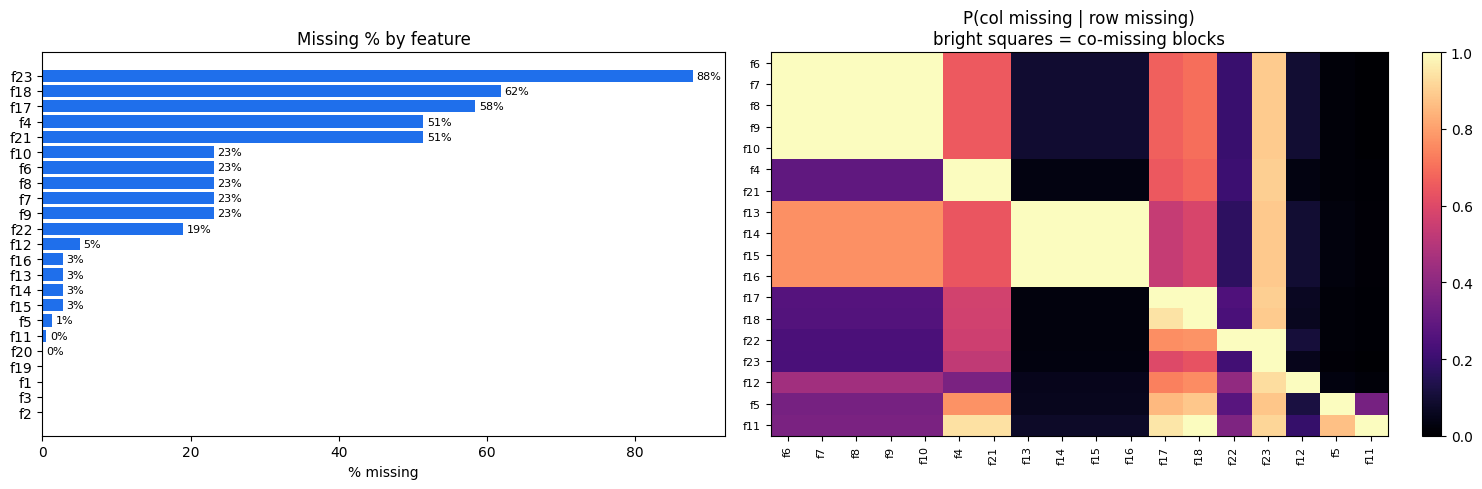

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (left) missing % bar
order = miss.sort_values('miss_%', ascending=True)
axes[0].barh(order.index, order['miss_%'], color='#1f6feb')
axes[0].set_xlabel('% missing'); axes[0].set_title('Missing % by feature')
for i,(f,v) in enumerate(zip(order.index, order['miss_%'])):
    if v>0: axes[0].text(v+0.5, i, f'{v:.0f}%', va='center', fontsize=8)

# (right) co-missing heatmap to show the blocks
block_cols = ['f6','f7','f8','f9','f10','f4','f21','f13','f14','f15','f16','f17','f18','f22','f23','f12','f5','f11']
H = pd.DataFrame(index=block_cols, columns=block_cols, dtype=float)
for a in block_cols:
    for b in block_cols:
        am = df[a].isna()
        H.loc[a,b] = (df[b].isna() & am).sum()/am.sum() if am.sum() else 0
im = axes[1].imshow(H.values.astype(float), cmap='magma', vmin=0, vmax=1, aspect='auto')
axes[1].set_xticks(range(len(block_cols))); axes[1].set_xticklabels(block_cols, rotation=90, fontsize=8)
axes[1].set_yticks(range(len(block_cols))); axes[1].set_yticklabels(block_cols, fontsize=8)
axes[1].set_title('P(col missing | row missing)\nbright squares = co-missing blocks')
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.show()

**Conclusion of Part A.** Four independent tests agree:
1. Whole feature *blocks* go missing together (≈100% co-missingness).
2. There is a logical funnel (`clicked ⊂ opened`).
3. Missing-indicators significantly predict other observed features (MAR).
4. Formal MCAR test / predictability proxy rejects MCAR.

So **a blank is not noise — it is a fact about the customer**: no industry-spend feed, not enrolled in rewards, no lending relationship, not an email engager. The imputation strategy must *preserve* that fact instead of erasing it.


# Part B — Recommended Missing-Value Strategy

Principle: **impute by mechanism, and keep the "was-missing" signal as an explicit flag** wherever missingness is structural. Concretely:

| Tier | Features | miss % | Mechanism | Action |
|---|---|---|---|---|
| Structural-zero: rewards | `f4`, `f21` | 51% | not enrolled / no rewards activity | fill **0** + flag `flg_rewards_missing` |
| Structural-zero: lend line | `f17`, `f18` | 58–62% | no lending relationship (real values ≥1000) | fill **0** + flag `flg_lendline_missing` |
| Structural-zero: industry spend | `f6`–`f10` | 23% | no industry-spend feed for segment | fill **0** + flag `flg_spend_detail_missing` |
| Engagement funnel | `f22` | 19% | not an email opener | fill **0** + flag `flg_email_missing` |
| Engagement funnel | `f23` | 88% | not an email clicker (⊂ opener) | fill **0** (covered by email flag) |
| Benefit-usage block | `f13`–`f16` | 2.7% | shared small segment | fill **0**/median + flag `flg_benefit_missing` |
| Low-rate noise | `f5`,`f11`,`f12`,`f19`,`f20` | <5% | near-random | **median** impute, no flag |

Why **not** mean-impute everything: the features are heavily skewed (so mean ≠ typical), and for the structural blocks the *typical* value of the segment really is ~0 (no line ⇒ no interest revenue; not enrolled ⇒ no points). Median is used only for the genuinely low-rate, near-random features. Why **flags**: they let the downstream profitability model treat "no lending relationship" as its own state rather than confusing a true 0 with an unknown.

> We deliberately avoid KNN / IterativeImputer here: at 500K×23 they are slow and, because the missingness is segment-driven rather than conditionally-Gaussian, they wouldn't beat median+flags.

### B1. Apply the strategy

In [13]:
clean = df.copy()

# --- groupings ---
STRUCT_ZERO = {
    'flg_rewards_missing'      : ['f4', 'f21'],
    'flg_lendline_missing'     : ['f17', 'f18'],
    'flg_spend_detail_missing' : ['f6', 'f7', 'f8', 'f9', 'f10'],
    'flg_email_missing'        : ['f22', 'f23'],   # f23 (clicked) nested in f22 (opened)
}
BENEFIT_BLOCK = ['f13', 'f14', 'f15', 'f16']       # 2.7% shared segment
LOW_RATE_MEDIAN = ['f5', 'f11', 'f12', 'f19', 'f20']

# 1) structural-zero blocks: add ONE flag per block (from its highest-missing column), then fill 0
for flag, cols in STRUCT_ZERO.items():
    driver = max(cols, key=lambda c: df[c].isna().mean())  # the block's defining column
    clean[flag] = df[driver].isna().astype('int8')
    for c in cols:
        clean[c] = clean[c].fillna(0)

# 2) benefit-usage block: one shared flag, fill with 0 (these are usage counts; absent => 0 usage)
clean['flg_benefit_missing'] = df['f13'].isna().astype('int8')
for c in BENEFIT_BLOCK:
    clean[c] = clean[c].fillna(0)

# 3) low-rate near-random: median impute, no flag
for c in LOW_RATE_MEDIAN:
    clean[c] = clean[c].fillna(df[c].median())

# 4) safety net: anything still missing (e.g. a stray NA) -> median
for c in FEATS:
    if clean[c].isna().any():
        clean[c] = clean[c].fillna(df[c].median())

print('Remaining missing values:', int(clean[FEATS].isna().sum().sum()))
flag_cols = [c for c in clean.columns if c.startswith('flg_')]
print('Flag columns added:', flag_cols)
clean[flag_cols].mean().round(3).rename('share_flagged')

Remaining missing values: 0
Flag columns added: ['flg_rewards_missing', 'flg_lendline_missing', 'flg_spend_detail_missing', 'flg_email_missing', 'flg_benefit_missing']


flg_rewards_missing         0.514
flg_lendline_missing        0.619
flg_spend_detail_missing    0.231
flg_email_missing           0.878
flg_benefit_missing         0.027
Name: share_flagged, dtype: float64

### B2. Before / after check — did we keep the signal?

In [14]:
summary = pd.DataFrame({
    'miss_%_before' : (100*df[FEATS].isna().mean()).round(2),
    'median_before' : df[FEATS].median().round(2),
    'median_after'  : clean[FEATS].median().round(2),
    'mean_before'   : df[FEATS].mean().round(2),
    'mean_after'    : clean[FEATS].mean().round(2),
})
summary

,miss_%_before,median_before,median_after,mean_before,mean_after
f1,0.00,0.00,0.00,2467.31,2467.31
f2,0.00,0.00,0.00,0.17,0.17
f3,0.00,0.00,0.00,0.11,0.11
f4,51.45,50705.19,0.00,126607.13,61473.33
f5,1.27,2165.85,2165.85,3464.81,3448.34
f6,23.14,4022.77,1621.49,10032.05,7710.67
f7,23.14,14396.27,6711.44,30821.55,23689.56
f8,23.14,303.99,36.75,1522.99,1170.58
f9,23.14,264.75,0.00,1651.74,1269.53
f10,23.14,1801.80,702.87,4536.38,3486.68


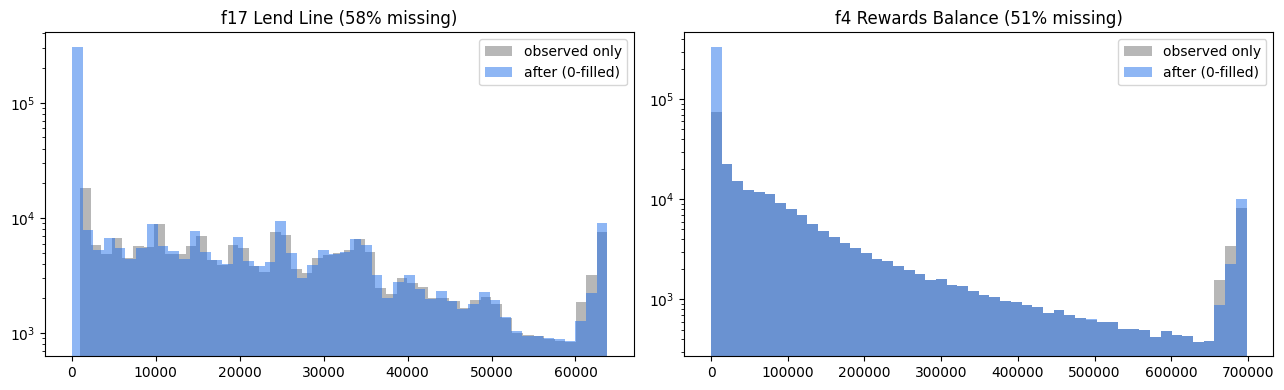

The tall bar at 0 after filling = the no-line / no-rewards segment, now explicitly flagged.


In [15]:
# Visual: distribution of a structural-zero feature before vs after, to confirm we added a 0-spike
# (the spike IS the segment we preserved via the flag), not smeared the real values.
fig, ax = plt.subplots(1, 2, figsize=(13,4))
for a, col, title in [(ax[0],'f17','f17 Lend Line (58% missing)'), (ax[1],'f4','f4 Rewards Balance (51% missing)')]:
    a.hist(df[col].dropna(), bins=50, alpha=0.6, label='observed only', color='#888')
    a.hist(clean[col], bins=50, alpha=0.5, label='after (0-filled)', color='#1f6feb')
    a.set_title(title); a.legend(); a.set_yscale('log')
plt.tight_layout(); plt.show()
print('The tall bar at 0 after filling = the no-line / no-rewards segment, now explicitly flagged.')

### B3. Save the cleaned CSV (read_csv → to_csv round-trip)

In [16]:
clean.to_csv(OUT_PATH, index=False)
print('Saved:', OUT_PATH, '| shape:', clean.shape)

# verify it reloads cleanly
check = pd.read_csv(OUT_PATH)
print('Reloaded shape:', check.shape, '| missing after reload:', int(check.isna().sum().sum()))
check.head()

Saved: campus_challenge_r1_data_clean.csv | shape: (500000, 29)


Reloaded shape: (500000, 29) | missing after reload: 0


,id,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20,f21,f22,f23,flg_rewards_missing,flg_lendline_missing,flg_spend_detail_missing,flg_email_missing,flg_benefit_missing
0,0,0.000000,0,1,98615.44,5620.938246,0.0000,0.00000,0.0000,0.000,0.0000,0.036093,4.0,0.0,0.0,0.0,49.280210,1960.0,1900.0,2.0,1.0,0.0,2.0,0.0,0,0,1,1,0
1,1,0.000000,0,0,21241.06,10196.878460,13865.4026,425.04840,27.9986,0.000,494.8428,0.000000,58.0,3.0,196.0,5.0,63.759364,34300.0,34650.0,3.0,2.0,163620.0,3.0,0.0,0,0,0,1,0
2,2,1224.690475,0,1,0.00,16.160000,0.0000,0.00000,0.0000,0.000,0.0000,0.182310,22.0,0.0,0.0,0.0,19.646836,0.0,0.0,1.0,1.0,0.0,9.0,0.0,1,1,1,1,0
3,3,0.000000,1,0,0.00,1635.316863,3231.1968,-269.15308,0.0000,0.000,48.5520,0.000040,19.0,0.0,0.0,0.0,9.143074,12348.0,12474.0,2.0,1.0,0.0,5.0,0.0,1,0,0,1,0
4,4,3824.366700,0,0,7140.87,5007.271790,4064.2152,16079.35060,377.9055,556.974,5354.3280,0.000253,3.0,0.0,0.0,11.0,63.759364,3672.0,3528.0,3.0,1.0,68640.0,0.0,0.0,0,0,0,1,0


### B4. (Reference only) peek at the submission template

Just so you can see what the final submission expects — `ID` + `Prediction`. We are **not** writing predictions here; this notebook ends at the cleaned dataset.

In [17]:
try:
    tmpl = pd.read_excel(TEMPLATE_PATH, sheet_name=None)
    for name, sheet in tmpl.items():
        print(f'--- sheet: {name} --- shape {sheet.shape}')
        print(sheet.head(3), '\n')
except FileNotFoundError:
    print('Template not found at TEMPLATE_PATH — skipping (reference only).')

--- sheet: Predictions --- shape (500000, 2)
   ID  Prediction
0   0         NaN
1   1         NaN
2   2         NaN 

--- sheet: Profitability Framework --- shape (10, 2)
                  Section  Response
0          Variables Used       NaN
1  Profitability Equation       NaN
2        Prediction Logic       NaN 



---
### Summary

- **Part A** proved, four independent ways, that missingness is **structured (MAR/MNAR), not MCAR**: co-missing blocks (~100% overlap), a clicked⊂opened funnel, missing-indicators that significantly predict other features, and a rejected MCAR test.
- **Part B** therefore imputed **by mechanism** — structural blanks → `0` **plus an explicit missing-flag** (so the model can use "this customer has no lending relationship" as real signal), and only the low-rate near-random features got **median** imputation.
- Output `campus_challenge_r1_data_clean.csv` has **zero missing values**, the original `id`, all `f1`–`f23`, and 6 new `flg_*` columns — ready to feed your profitability-equation step.